# Trabalho 3 – Privacidade Diferencial 

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

SAIDA = "resultados"
os.makedirs(SAIDA, exist_ok=True)

##  pre processamento

In [34]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("wenruliu/adult-income-dataset")

df = pd.read_csv(path + "/adult.csv")

df = df.drop(columns=["fnlwgt", "education", "capital-gain", "capital-loss", "hours-per-week"])

df = df[(df != "?").all(axis=1)].reset_index(drop=True)
print("após remover '?':", df.shape)
print("'?' restantes:", (df == "?").sum().sum())

for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].astype("category").cat.codes


print(df.dtypes)
df.head()

após remover '?': (45222, 10)
'?' restantes: 0
age                int64
workclass           int8
educational-num    int64
marital-status      int8
occupation          int8
relationship        int8
race                int8
gender              int8
native-country      int8
income              int8
dtype: object


,age,workclass,educational-num,marital-status,occupation,relationship,race,gender,native-country,income
0,25,2,7,4,6,3,2,1,38,0
1,38,2,9,2,4,0,4,1,38,0
2,28,1,12,2,10,0,4,1,38,1
3,44,2,10,2,6,0,2,1,38,1
4,34,2,6,4,7,1,4,1,38,0


## divisão 70% treino, 30% teste

In [ ]:
# divisao treino/teste

coluna_rotulo = df.columns[-1] # income
X = df.drop(columns=coluna_rotulo).to_numpy()
y = df[coluna_rotulo].to_numpy().astype(int)
n_classes = int(y.max()) + 1

rng = np.random.default_rng(42)
perm = rng.permutation(len(X))
n_teste = int(round(0.3 * len(X)))

idx_teste, idx_treino = perm[:n_teste], perm[n_teste:]

X_treino, X_teste = X[idx_treino], X[idx_teste]
y_treino, y_teste = y[idx_treino], y[idx_teste]

print("treino:", X_treino.shape, "| teste:", X_teste.shape, "| classes:", n_classes)

treino: (31655, 9) | teste: (13567, 9) | classes: 2


## funções kNN  e mecanismo de laplace

In [ ]:
K = 10
RAIO = 6.0
EPSILONS = [0.5, 1, 5, 10]
SENSIBILIDADE = 1.0
def estatisticas_vizinhanca(X_treino, y_treino, X_teste, k, raio, n_classes, bloco=256):

    Xtr = X_treino.astype(np.float64)
    Xte = X_teste.astype(np.float64)
    quad_treino = (Xtr ** 2).sum(axis=1)
    one_hot = np.eye(n_classes)[y_treino]

    pred_knn = np.empty(len(Xte), dtype=int)
    contagens = np.zeros((len(Xte), n_classes))
    raio2 = raio ** 2

    for inicio in range(0, len(Xte), bloco):
        B = Xte[inicio:inicio + bloco]
        d2 = (B ** 2).sum(axis=1)[:, None] + quad_treino[None, :] - 2.0 * B @ Xtr.T
        np.maximum(d2, 0.0, out=d2)

        # k vizinhos mais próximos -> classe com mais voto 
        idx = np.argpartition(d2, k - 1, axis=1)[:, :k]  # pega posições mais proximas
        votos = np.stack([(y_treino[idx] == c).sum(axis=1) for c in range(n_classes)], axis=1)
        pred_knn[inicio:inicio + bloco] = votos.argmax(axis=1) 

        
        dentro = (d2 <= raio2).astype(np.float64) # contagem por classe dentro do raio
        contagens[inicio:inicio + bloco] = dentro @ one_hot  # quantidade de vizinhos por classe dentro do raio

    return pred_knn, contagens


def contagens_laplace(contagens, eps, n_teste, n_classes, rng, modo="baseline_sequencial"):
    """  
    modo="baseline_sequencial": eps' = eps / (n_teste * n_classes)  
    """
    eps_consulta = eps / n_teste
    eps_linha = eps_consulta / n_classes if modo == "baseline_sequencial" else eps_consulta
    escala = SENSIBILIDADE / eps_linha
    ruidosas = contagens + rng.laplace(loc=0.0, scale=escala, size=contagens.shape) # adição de ruído laplaciano, com sorteio de ruído para cada consulta cada teste, cada classe
    return ruidosas, eps_linha, escala

## kNN

In [37]:
pred_knn, contagens = estatisticas_vizinhanca(X_treino, y_treino, X_teste, K, RAIO, n_classes)

acc_knn = (pred_knn == y_teste).mean()
print(f"kNN tradicional (k={K}): acurácia = {acc_knn:.4f}")

pd.DataFrame({"idx_teste": np.arange(n_teste), "y_real": y_teste, "y_pred": pred_knn}) \
    .to_csv(os.path.join(SAIDA, "pred_knn.csv"), index=False)

kNN tradicional (k=10): acurácia = 0.8164


## kNN com laplace para cada ε


In [ ]:
rng_ruido = np.random.default_rng(42)      # um sorteador só, usado em sequência

linhas = []
for eps in EPSILONS:
    ruidosas, eps_linha, escala = contagens_laplace(contagens, eps, n_teste, n_classes, rng_ruido)
    pred = ruidosas.argmax(axis=1)

    saida_eps = pd.DataFrame({"idx_teste": np.arange(n_teste), "y_real": y_teste, "y_pred": pred})
    for c in range(n_classes):
        saida_eps[f"contagem_ruidosa_{c}"] = ruidosas[:, c]
    saida_eps.to_csv(os.path.join(SAIDA, f"pred_dp_eps_{eps}.csv"), index=False)

    linhas.append({
        "epsilon": eps, "eps_por_contagem": eps_linha, "escala_laplace": escala,
        "acc_real": (pred == y_teste).mean(),
        "acc_vs_knn": (pred == pred_knn).mean(),
        "acc_knn_sem_privacidade": acc_knn,
    })

resumo = pd.DataFrame(linhas)
resumo.to_csv(os.path.join(SAIDA, "resumo_acuracia.csv"), index=False)
resumo

,epsilon,eps_por_contagem,escala_laplace,acc_real,acc_vs_knn,acc_knn_sem_privacidade
0,0.5,0.000018,54268.0,0.503280,0.503501,0.816393
1,1.0,0.000037,27134.0,0.508587,0.508956,0.816393
2,5.0,0.000184,5426.8,0.528267,0.537481,0.816393
3,10.0,0.000369,2713.4,0.556129,0.566964,0.816393


## Gráfico

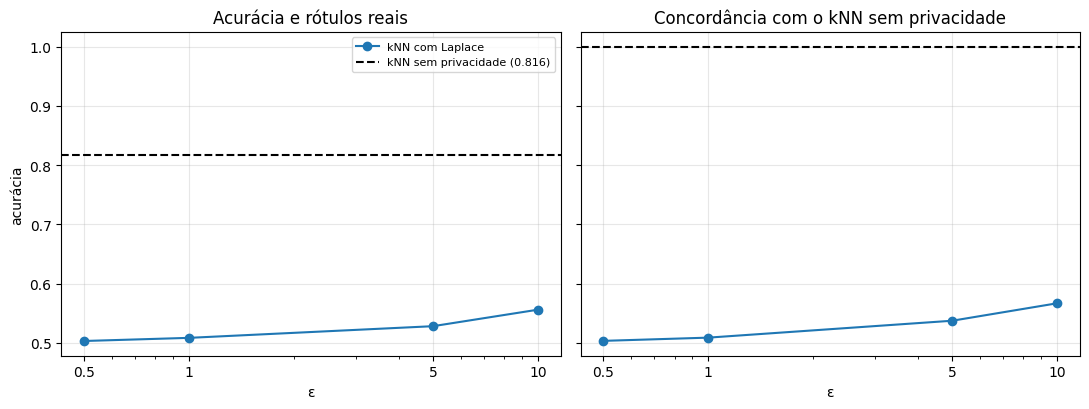

In [39]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, col, titulo, ref in [(eixos[0], "acc_real", "Acurácia e rótulos reais", acc_knn),
                             (eixos[1], "acc_vs_knn", "Concordância com o kNN sem privacidade", 1.0)]:
    ax.plot(resumo["epsilon"], resumo[col], marker="o", label="kNN com Laplace")
    ax.axhline(ref, color="k", linestyle="--", label=f"kNN sem privacidade ({ref:.3f})")
    ax.set_xscale("log")
    ax.set_xticks(EPSILONS)
    ax.set_xticklabels([str(e) for e in EPSILONS])
    ax.set_xlabel("ε")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
eixos[0].set_ylabel("acurácia")
eixos[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(SAIDA, "grafico_acuracia.png"), dpi=150)
plt.show()

In [40]:
print(f"|Xtest| = {n_teste}, L = {n_classes}")
for e in EPSILONS:
    print(f"ε={e}: ε' por contagem = {e/(n_teste*n_classes):.2e}  -> escala do Laplace = {n_teste*n_classes/e:,.0f}")
print()


|Xtest| = 13567, L = 2
ε=0.5: ε' por contagem = 1.84e-05  -> escala do Laplace = 54,268
ε=1: ε' por contagem = 3.69e-05  -> escala do Laplace = 27,134
ε=5: ε' por contagem = 1.84e-04  -> escala do Laplace = 5,427
ε=10: ε' por contagem = 3.69e-04  -> escala do Laplace = 2,713

